# PS1 — Equities: intraday descriptive statistics

Two Nasdaq-listed stocks at opposite ends of the size distribution, over one full
regular session (**2026-09-02, 09:30–16:00 ET**):

| | ticker | price on the day | market cap |
|---|---|---|---|
| mega cap | **NVDA** | \$219 → \$224 | ~\$5.5T |
| micro cap | **GPRO** | \$1.22 → \$1.71 (+40%) | ~\$0.27B |

The source is Databento MBO for `XNAS.ITCH` — every add, cancel, fill and trade
message Nasdaq published, one row each. `mbo.py` replays those messages into a
full limit order book and hands back three objects per symbol:

* `trades` — the trade tape, signed, with the quote prevailing at each print
* `quotes` — the BBO, one row per change
* `grid` — the book sampled at the end of every second, plus resting depth by
  distance from the mid

Parts (a)–(k) are computed by `hfstats.py`, which is written once against these
objects and is also what the currencies notebook runs, so the two panels are
measured with one definition of every statistic.

Three things about the raw feed worth stating up front, because they shape the
numbers below:

1. **An execution emits three records** — `T` (the trade), `F` (the fill against the
   resting order) and `C` (which removes the shares). Only `A` and `C` move the book;
   counting `F` as well would double the depth removed, and counting it as a trade
   would double the volume.
2. **`T.side` is the aggressor**, except for non-displayed executions and the cross,
   which arrive unsigned (22% of NVDA prints). Those are signed with the quote rule.
3. **The book has to be built from the pre-market.** Databento snapshots the book only
   at UTC midnight, so the request runs from there (20:00 ET the evening before, when
   Nasdaq's book is empty) to the close and the pre-market is replayed before the
   first 09:30 snapshot; only the regular session is recorded. Started from an empty
   book at 09:30 instead, 0.3% of NVDA's and 0.8% of GPRO's session cancels reference
   an order never seen — resting pre-open orders, which are *not* re-added after the
   cross — and the resting depth within \$0.50 of the mid is understated by 7% (NVDA)
   and 37% (GPRO) at 09:31, still 2% and 22% at 10:00, and 0.2% and 8% on average over
   the day. Touch depth and spreads are unaffected for NVDA, and GPRO's touch by <1%.
   With the full-day replay `Day.unknown_cancels` is zero for both names.

In [1]:
import numpy as np
import pandas as pd

import hfstats as hs
import mbo
import plots
from hfstats import FREQS, MINUTE, summary, tape

# Approximate, from the latest filings — the only input here that is not in the data.
SHARES_OUT = {"NVDA": 24.4e9, "GPRO": 0.16e9}

days = mbo.load("NVDA", "GPRO")
nvda, gpro = days["NVDA"], days["GPRO"]

days

{'NVDA': <Day NVDA: 347,782 trades, 3,294,069 quote updates>,
 'GPRO': <Day GPRO: 29,312 trades, 205,133 quote updates>}

## Choice of stocks

Size shows up in the data long before we reach the statistics: NVDA trades ~12x as
often and turns over ~180x the dollars, but GPRO's quoted spread is ~93x wider in
relative terms. GPRO also happened to rally 40% on this day, from \$1.22 to \$1.71
in a steady climb between noon and 15:30 — worth keeping in mind wherever a GPRO
statistic is quoted in basis points of a moving price. The opening cross
is excluded from the tape throughout (`hfstats.tape`): it prints once, unsigned, and
is ~30x a normal trade, so left in it dominates the first minute of every trade
statistic.

In [2]:
pd.DataFrame({
    d.symbol: {
        "last trade": tape(d).price.iloc[-1],
        "shares outstanding": SHARES_OUT[d.symbol],
        "market cap ($bn)": SHARES_OUT[d.symbol] * tape(d).price.iloc[-1] / 1e9,
        "trades": len(tape(d)),
        "share volume": tape(d)["size"].sum(),
        "dollar volume ($mm)": tape(d).value.sum() / 1e6,
        "quote updates": len(d.quotes),
        "mean spread ($)": d.grid.spread.mean(),
        "mean spread (bps)": (1e4 * d.grid.spread / d.grid.mid).mean(),
    } for d in (nvda, gpro)
})

,NVDA,GPRO
last trade,2.244000e+02,1.705000e+00
shares outstanding,2.440000e+10,1.600000e+08
market cap ($bn),5.475360e+03,2.728000e-01
trades,3.477810e+05,2.931100e+04
share volume,2.277871e+07,1.851121e+07
dollar volume ($mm),5.110478e+03,2.812093e+01
quote updates,3.294069e+06,2.051330e+05
mean spread ($),1.699829e-02,1.003632e-02
mean spread (bps),7.573769e-01,7.065533e+01


## Part (a) — dollar trading volume per minute

Traded notional, `price x size` summed within each minute.

In [3]:
a = {s: hs.dollar_volume_per_minute(d) for s, d in days.items()}
pd.concat({s: summary(v) for s, v in a.items()}, names=["symbol", "series"]).round(0)

,,count,mean,std,min,25%,50%,75%,max
symbol,series,,,,,,,,
NVDA,dollar_volume,390.0,13103791.0,12300020.0,2061858.0,6003602.0,10097005.0,16248732.0,151366815.0
GPRO,dollar_volume,390.0,72105.0,105071.0,0.0,4728.0,36328.0,89190.0,719389.0


## Part (b) — number of trades and number of orders per minute

Trades are `T` prints; orders are `A` (add-order) messages, which only a full-depth
feed like ITCH exposes — these are the *displayed* orders, which is what the FAQ
asks for (hidden orders carry no add message and are seen only when they execute).
Cancels are shown alongside: the ratio of cancels to adds is the usual read on how
much of the book is fleeting.

In [4]:
b = {s: hs.counts_per_minute(d) for s, d in days.items()}
pd.concat({s: summary(v) for s, v in b.items()}, names=["symbol", "series"]).round(1)

count     mean      std     min     25%     50%      75%  \
symbol series                                                              
NVDA   trades   390.0    891.7    739.8   163.0   404.2   639.5   1150.8   
       adds     390.0  12593.6  10151.4  3702.0  6936.5  9877.5  16246.0   
       cancels  390.0  12188.8   6932.5  3694.0  6903.0  9896.0  16155.8   
       fills    390.0    697.4    577.9   132.0   317.2   501.0    886.5   
GPRO   trades   390.0     75.2    110.3     0.0    14.0    46.0    100.8   
       adds     390.0    401.7    402.7    26.0   161.5   304.5    525.8   
       cancels  390.0    413.3    369.2    24.0   164.2   318.0    547.5   
       fills    390.0     51.4     73.8     0.0     2.0    30.0     69.0   

                     max  
symbol series             
NVDA   trades     7074.0  
       adds     160066.0  
       cancels   44388.0  
       fills      5736.0  
GPRO   trades     1377.0  
       adds       4483.0  
       cancels    2793.0  
       fills       779.0

In [5]:
pd.DataFrame({s: {
    "orders per trade": v.adds.sum() / max(v.trades.sum(), 1),
    "cancels per add": v.cancels.sum() / max(v.adds.sum(), 1),
} for s, v in b.items()}).round(2)

,NVDA,GPRO
orders per trade,14.12,5.34
cancels per add,0.97,1.03


## Part (c) — open, close, high and low prices

Both readings: the session's OHLC, and the per-minute trade-price OHLC. Minutes with
no prints come back as `NaN` rather than being forward-filled, so the `count` column
shows how often each name actually trades.

In [6]:
pd.DataFrame({s: hs.ohlc_daily(d) for s, d in days.items()})

,NVDA,GPRO
open,218.87,1.220
high,227.94,1.790
low,218.47,1.180
close,224.40,1.705


In [7]:
c = {s: hs.ohlc_per_minute(d) for s, d in days.items()}
pd.concat({s: summary(v) for s, v in c.items()}, names=["symbol", "series"]).round(4)

count      mean     std      min       25%       50%       75%  \
symbol series                                                                   
NVDA   open    390.0  224.6749  1.9521  218.870  224.0600  224.8175  225.9850   
       high    390.0  224.8272  1.9167  219.670  224.1938  224.8850  226.0638   
       low     390.0  224.5518  1.9774  218.470  223.9912  224.7325  225.8425   
       close   390.0  224.6879  1.9299  219.205  224.0600  224.8200  225.9775   
GPRO   open    376.0    1.4475  0.1807    1.185    1.2750    1.4050    1.6350   
       high    376.0    1.4538  0.1826    1.195    1.2800    1.4150    1.6500   
       low     376.0    1.4421  0.1783    1.180    1.2750    1.4050    1.6300   
       close   376.0    1.4488  0.1807    1.185    1.2750    1.4075    1.6362   

                   max  
symbol series           
NVDA   open    227.795  
       high    227.940  
       low     227.600  
       close   227.800  
GPRO   open      1.785  
       high      1.790  
       low       1.770  
       close     1.785

## Part (d) — VWAP per minute

Size-weighted average trade price, `sum(p*q) / sum(q)` within the minute.

In [8]:
d_ = {s: hs.vwap_per_minute(d) for s, d in days.items()}
pd.concat({s: summary(v) for s, v in d_.items()}, names=["symbol", "series"]).round(4)

,,count,mean,std,min,25%,50%,75%,max
symbol,series,,,,,,,,
NVDA,vwap,390.0,224.6988,1.9394,219.0234,224.0735,224.8235,225.9637,227.7349
GPRO,vwap,376.0,1.4481,0.1802,1.1900,1.2793,1.4098,1.6399,1.7794


## Part (e) — BBO spread and depth per minute

Averaged over end-of-second book snapshots, so every second carries equal weight —
a time-weighted average, rather than one weighted by how often each name requotes.

In [9]:
e = {s: hs.spread_depth_per_minute(d) for s, d in days.items()}
pd.concat({s: summary(v) for s, v in e.items()}, names=["symbol", "series"]).round(4)

count        mean         std         min         25%  \
symbol series                                                              
NVDA   spread      390.0      0.0170      0.0038      0.0105      0.0152   
       spread_bps  390.0      0.7574      0.1742      0.4683      0.6686   
       bid_sz      390.0    238.9403    141.1244     66.4667    166.2625   
       ask_sz      390.0    223.4137    138.2796     67.7000    145.2625   
       depth       390.0    462.3541    219.9650    143.3167    339.9917   
GPRO   spread      390.0      0.0100      0.0002      0.0100      0.0100   
       spread_bps  390.0     70.6553      8.3985     56.2013     62.3211   
       bid_sz      390.0  25165.3405  32300.7652   1386.9667  10686.9958   
       ask_sz      390.0  25516.5075  19263.9455   3047.5000  12597.3958   
       depth       390.0  50681.8479  39222.3692  11193.1833  27555.4125   

                          50%         75%          max  
symbol series                                           
NVDA   spread          0.0162      0.0178       0.0537  
       spread_bps      0.7193      0.7940       2.4510  
       bid_sz        207.0750    257.7917    1586.4833  
       ask_sz        186.9833    234.0208    1283.9167  
       depth         403.6750    513.5083    1980.2833  
GPRO   spread          0.0100      0.0100       0.0122  
       spread_bps     71.1744     78.4314      89.1070  
       bid_sz      15433.9750  26504.6083  215645.9667  
       ask_sz      20642.6583  33322.1708  132471.1833  
       depth       41916.6917  60089.0833  271918.7833

## Part (f) — depth within twice the day's average spread

Shares resting within one average spread either side of the mid, i.e. inside a band
of **twice** the day's mean quoted spread. The best bid sits half a spread from the
mid, so the band is empty exactly when the prevailing spread exceeds twice its
average — `frac_empty` reports how often that happens. Note the degenerate case: if a
name's spread is always one tick, the band reaches no further than the BBO and (f)
just reproduces the depth from (e). GPRO — one tick wide in 99.6% of seconds — is
exactly that case; NVDA's 1.7-cent average spread puts the band one level past the
touch.

In [10]:
f = {s: hs.band_depth_per_minute(d) for s, d in days.items()}
for s, v in f.items():
    print(f"{s}: band = ${v.attrs['band']:.4f} wide")
pd.concat({s: summary(v) for s, v in f.items()}, names=["symbol", "series"]).round(4)

NVDA: band = $0.0340 wide
GPRO: band = $0.0201 wide


count        mean         std         min         25%  \
symbol series                                                              
NVDA   band_depth  390.0    718.3977    379.8359     77.9667    521.6167   
       frac_empty  390.0      0.0105      0.0698      0.0000      0.0000   
GPRO   band_depth  390.0  50681.8479  39222.3692  11193.1833  27555.4125   
       frac_empty  390.0      0.0000      0.0000      0.0000      0.0000   

                          50%         75%          max  
symbol series                                           
NVDA   band_depth    647.8750    835.2583    3922.0000  
       frac_empty      0.0000      0.0000       0.8333  
GPRO   band_depth  41916.6917  60089.0833  271918.7833  
       frac_empty      0.0000      0.0000       0.0000

## Part (g) — 5-second price impact per minute

Within each minute, regress the 5-second midquote return following each print on the
sign of that print:

$$10^4 \cdot \log\!\big(m_{t+5s}/m_t\big) \;=\; \alpha + \lambda \, s_t + \varepsilon_t,
\qquad s_t \in \{-1, +1\}$$

$\lambda$ is the midquote move a buy pushes through, in basis points. Because $s_t$ is
binary the slope is just the difference in mean response between buys and sells,
halved — computed in closed form rather than by looping OLS over 390 minutes. Minutes
with fewer than ten prints, or with trades on one side only, cannot identify it and
are left blank.

In [11]:
g = {s: hs.price_impact_per_minute(d) for s, d in days.items()}
pd.concat({s: summary(v) for s, v in g.items()}, names=["symbol", "series"]).round(4)

count      mean       std       min       25%       50%  \
symbol series                                                                
NVDA   lambda_bps  390.0    0.3339    0.2711   -0.5065    0.1598    0.2992   
       alpha_bps   390.0    0.0220    0.9893   -4.7614   -0.4437    0.0342   
       n_trades    390.0  886.4487  701.8272  163.0000  404.2500  639.5000   
GPRO   lambda_bps  252.0   22.7107   16.5412   -6.7449   10.5487   22.6093   
       alpha_bps   252.0    1.8705   25.2295  -73.0588  -12.5771    0.0000   
       n_trades    390.0   75.1026  110.0890    0.0000   14.0000   46.0000   

                         75%        max  
symbol series                            
NVDA   lambda_bps     0.4567     1.7606  
       alpha_bps      0.4581     8.5757  
       n_trades    1150.7500  5090.0000  
GPRO   lambda_bps    33.4565    66.8341  
       alpha_bps     17.0596   113.4971  
       n_trades     100.7500  1377.0000

The mean of per-minute slopes weights a thin minute as much as a busy one. The
pooled alternative — every print in the session in one regression, with Newey–West
standard errors for the overlapping 5-second windows — is the single number an
economist would quote, and it comes with a t-statistic.

In [12]:
pd.DataFrame({s: hs.price_impact_pooled(d) for s, d in days.items()}).T.round(4)

,lambda_bps,se_bps,t,n
NVDA,0.4608,0.0167,27.6246,345715.0
GPRO,26.6512,0.9677,27.5407,29290.0


## Part (h) — one-second and one-minute midquote and transaction price series

The last quote and the last print in each interval. Intervals with no trade inherit
the previous price, so the two series stay on a common clock.

In [13]:
h = {s: {fq: hs.price_series(d, fq) for fq in FREQS} for s, d in days.items()}
pd.concat({(s, fq): summary(v) for s, d_ in h.items() for fq, v in d_.items()},
          names=["symbol", "freq", "series"]).round(4)

count      mean     std      min       25%       50%  \
symbol freq series                                                           
NVDA   1s   mid     23400.0  224.6913  1.9412  218.515  224.0750  224.8100   
            trade   23400.0  224.6913  1.9411  218.530  224.0800  224.8100   
       1min mid       390.0  224.6883  1.9307  219.200  224.0538  224.8175   
            trade     390.0  224.6879  1.9299  219.205  224.0600  224.8200   
GPRO   1s   mid     23400.0    1.4415  0.1798    1.185    1.2750    1.4050   
            trade   23400.0    1.4418  0.1799    1.180    1.2750    1.4050   
       1min mid       390.0    1.4423  0.1803    1.185    1.2750    1.4050   
            trade     390.0    1.4427  0.1804    1.185    1.2750    1.4050   

                         75%      max  
symbol freq series                     
NVDA   1s   mid     225.9600  227.935  
            trade   225.9600  227.940  
       1min mid     225.9850  227.800  
            trade   225.9775  227.800  
GPRO   1s   mid       1.6350    1.785  
            trade     1.6350    1.790  
       1min mid       1.6350    1.785  
            trade     1.6338    1.785

## Part (i) — log returns

$r_t = \log(p_t) - \log(p_{t-1})$, in basis points, for both series.

In [14]:
i = {s: {fq: hs.log_returns(v) for fq, v in d_.items()} for s, d_ in h.items()}
pd.concat({(s, fq): summary(1e4 * v) for s, d_ in i.items() for fq, v in d_.items()},
          names=["symbol", "freq", "series"]).round(4)

count    mean      std       min      25%     50%  \
symbol freq series                                                        
NVDA   1s   mid     23399.0  0.0107   1.1773  -11.3836  -0.4451  0.0000   
            trade   23399.0  0.0108   1.1879  -11.6111  -0.4449  0.0000   
       1min mid       389.0  0.5529   8.3707  -25.0359  -3.7800  0.4457   
            trade     389.0  0.5523   8.3668  -25.2626  -3.9577  0.4453   
GPRO   1s   mid     23399.0  0.1430  10.9912 -194.8114   0.0000  0.0000   
            trade   23399.0  0.1430  11.0635 -166.9488   0.0000  0.0000   
       1min mid       389.0  8.7101  80.5264 -238.1065   0.0000  0.0000   
            trade     389.0  8.8161  82.6927 -206.9039 -35.5240  0.0000   

                        75%       max  
symbol freq series                     
NVDA   1s   mid      0.4453   13.6684  
            trade    0.4448   13.7005  
       1min mid      4.6866   58.4201  
            trade    4.4783   58.8743  
GPRO   1s   mid      0.0000  204.0887  
            trade    0.0000  237.7022  
       1min mid     59.8804  418.1794  
            trade   40.0802  431.2443

## Part (j) — realized variance

$RV = \sum_t r_t^2$ over the session, for each series and sampling frequency. Gaps
between the midquote and transaction figures, and between the two frequencies, are
where microstructure noise shows up — the finer the sampling, and the closer to the
traded price rather than the mid, the more of the variance is noise rather than signal.

In [15]:
pd.concat({(s, fq): hs.realized_variance(v) for s, d_ in i.items() for fq, v in d_.items()},
          names=["symbol", "freq", "series"])

n  realized_var  realized_vol  annualized_vol
symbol freq series                                                   
NVDA   1s   mid     23399      0.000324      0.018010        0.285896
            trade   23399      0.000330      0.018171        0.288459
       1min mid       389      0.000273      0.016524        0.262318
            trade     389      0.000273      0.016517        0.262195
GPRO   1s   mid     23399      0.028271      0.168141        2.669148
            trade   23399      0.028644      0.169246        2.686697
       1min mid       389      0.025455      0.159546        2.532716
            trade     389      0.026834      0.163811        2.600421

### Volatility signature

RV of each series against the interval it is sampled at, in bps². For a price
contaminated by bid–ask bounce this curve falls as the interval lengthens; the share
of intervals with no price change shows how much of the high-frequency figure is
instead being held *down* by discreteness (the currencies notebook finds that effect
dominates for EBS mids).

In [16]:
_freqs = ["1s", "2s", "5s", "10s", "30s", MINUTE, "2min", "5min"]


def _signature(series):
    """RV in bps^2, and the share of intervals with no price change, by frequency."""
    out = {}
    for fq in _freqs:
        r = np.log(series.resample(fq).last().ffill().dropna()).diff().dropna()
        out[fq] = {"RV (bps^2)": 1e8 * (r ** 2).sum(), "zero returns (%)": 100 * (r == 0).mean()}
    return pd.DataFrame(out).T


pd.concat({(s, k): _signature(src) for s, d in days.items()
           for k, src in (("mid", d.grid.mid), ("trade", tape(d).price))},
          axis=1, names=["symbol", "series", ""]).round(1)

symbol       NVDA                                                    GPRO  \
series        mid                       trade                         mid   
       RV (bps^2) zero returns (%) RV (bps^2) zero returns (%) RV (bps^2)   
1s        32435.1             21.0    33019.3             31.3  2827123.2   
2s        33443.2             11.4    33695.7             17.7  2746051.3   
5s        33956.0              5.7    34154.5              8.3  2664339.7   
10s       34433.1              3.2    34432.4              5.6  2557414.1   
30s       34950.8              1.7    34976.6              3.1  2395240.5   
1min      27305.9              1.3    27280.1              0.5  2545496.2   
2min      24601.8              0.5    24485.7              1.0  2531544.3   
5min      22256.3              0.0    21951.8              1.3  2525429.8   

symbol                                               
series                       trade                   
       zero returns (%) RV (bps^2) zero returns (%)  
1s                 97.4  2864420.5             94.2  
2s                 95.3  2810109.2             89.5  
5s                 90.0  2676451.6             78.5  
10s                83.3  2586103.6             66.9  
30s                65.7  2681667.2             43.8  
1min               49.9  2683408.0             31.1  
2min               38.7  2716714.4             20.6  
5min               22.1  2714641.4             14.3

## Part (k) — autocorrelation of returns

The Box–Pierce $Q$ statistic tests whether the first $k$ autocorrelations are jointly
zero; the ACF and partial ACF show where any dependence sits. Two things to read off:
whether transaction returns are more negatively autocorrelated at lag 1 than midquote
returns (the bid-ask bounce, which only bites when sampling is fast enough that
consecutive observations straddle the spread), and whether the sign flips between the
one-second and one-minute clocks.

In [17]:
pd.concat({(s, fq): hs.autocorrelation(v) for s, d_ in i.items() for fq, v in d_.items()},
          names=["symbol", "freq", "lag"]).round(4)

mid                              trade                   \
                    acf    pacf  bp_stat bp_pvalue     acf    pacf  bp_stat   
symbol freq lag                                                               
NVDA   1s   1    0.0249  0.0249  14.5089    0.0001  0.0173  0.0173   7.0163   
            2    0.0091  0.0085  16.4447    0.0003  0.0130  0.0127  10.9973   
            3    0.0147  0.0143  21.4933    0.0001  0.0131  0.0127  15.0257   
            4   -0.0069 -0.0077  22.6057    0.0002 -0.0100 -0.0106  17.3510   
            5   -0.0114 -0.0113  25.6587    0.0001 -0.0132 -0.0132  21.4511   
            6   -0.0054 -0.0049  26.3338    0.0002 -0.0015 -0.0009  21.5012   
            7   -0.0081 -0.0075  27.8847    0.0002 -0.0090 -0.0084  23.3973   
            8    0.0165  0.0173  34.2482    0.0000  0.0114  0.0120  26.4316   
            9   -0.0074 -0.0081  35.5161    0.0000 -0.0043 -0.0047  26.8580   
            10  -0.0059 -0.0058  36.3318    0.0001 -0.0030 -0.0031  27.0689   
       1min 1   -0.1182 -0.1185   5.4309    0.0198 -0.1203 -0.1206   5.6324   
            2    0.0231  0.0094   5.6393    0.0596  0.0217  0.0073   5.8153   
            3    0.1176  0.1241  11.0176    0.0116  0.1169  0.1231  11.1349   
            4   -0.0994 -0.0744  14.8584    0.0050 -0.0922 -0.0665  14.4412   
            5    0.0981  0.0765  18.5983    0.0023  0.0923  0.0721  17.7523   
            6    0.0225  0.0333  18.7947    0.0045  0.0298  0.0399  18.0967   
            7    0.0489  0.0744  19.7265    0.0062  0.0423  0.0677  18.7912   
            8    0.0469  0.0343  20.5826    0.0083  0.0488  0.0376  19.7185   
            9    0.0203  0.0367  20.7421    0.0138  0.0146  0.0282  19.8010   
            10  -0.0270 -0.0414  21.0262    0.0209 -0.0202 -0.0322  19.9591   
GPRO   1s   1   -0.0215 -0.0215  10.7748    0.0010 -0.0224 -0.0224  11.7875   
            2   -0.0230 -0.0235  23.1737    0.0000 -0.0174 -0.0180  18.9098   
            3   -0.0128 -0.0139  27.0287    0.0000 -0.0091 -0.0099  20.8537   
            4    0.0091  0.0079  28.9505    0.0000  0.0025  0.0018  21.0030   
            5   -0.0136 -0.0139  33.2840    0.0000 -0.0155 -0.0158  26.6588   
            6   -0.0108 -0.0112  36.0080    0.0000 -0.0112 -0.0119  29.5718   
            7   -0.0042 -0.0051  36.4263    0.0000  0.0077  0.0066  30.9505   
            8   -0.0012 -0.0024  36.4621    0.0000  0.0032  0.0028  31.1834   
            9    0.0039  0.0036  36.8208    0.0000  0.0080  0.0083  32.6875   
            10  -0.0023 -0.0023  36.9430    0.0001 -0.0011 -0.0007  32.7184   
       1min 1    0.0383  0.0384   0.5719    0.4495  0.0309  0.0310   0.3711   
            2    0.0097  0.0083   0.6087    0.7376 -0.0132 -0.0142   0.4389   
            3    0.0250  0.0246   0.8520    0.8370  0.0315  0.0327   0.8253   
            4    0.0251  0.0235   1.0979    0.8946  0.0122  0.0101   0.8831   
            5   -0.1544 -0.1591  10.3755    0.0653 -0.1178 -0.1194   6.2813   
            6    0.0483  0.0622  11.2835    0.0800  0.0353  0.0436   6.7665   
            7   -0.0627 -0.0693  12.8151    0.0767 -0.0745 -0.0840   8.9260   
            8   -0.0099  0.0029  12.8531    0.1170  0.0093  0.0246   8.9598   
            9    0.0837  0.0961  15.5785    0.0762  0.0862  0.0872  11.8472   
            10   0.0043 -0.0319  15.5856    0.1121 -0.0115 -0.0302  11.8989   

                           
                bp_pvalue  
symbol freq lag            
NVDA   1s   1      0.0081  
            2      0.0041  
            3      0.0018  
            4      0.0017  
            5      0.0007  
            6      0.0015  
            7      0.0015  
            8      0.0009  
            9      0.0015  
            10     0.0025  
       1min 1      0.0176  
            2      0.0546  
            3      0.0110  
            4      0.0060  
            5      0.0033  
            6      0.0060  
            7      0.0089  
            8      0.0115  
            9      0.0192  
      

## Intraday plots

The liquidity measures — spread, BBO depth and price impact — per five-minute
interval, then the variance and lag-1 autocorrelation of one-minute transaction
returns per thirty-minute interval, then the ACF of each return series to ten lags.
One panel per stock, because the two share units but differ in level by orders of
magnitude.

In [18]:
liq5 = {s: plots.liquidity_by_interval(d) for s, d in days.items()}
pd.concat({s: summary(v) for s, v in liq5.items()}, names=["symbol", "series"]).round(3)

count       mean        std        min        25%  \
symbol series                                                          
NVDA   spread_bps   78.0      0.757      0.162      0.532      0.677   
       depth        78.0    462.354    160.456    199.787    365.399   
       lambda_bps   78.0      0.383      0.185      0.119      0.268   
       n_trades     78.0   4432.244   2863.426   1194.000   2152.000   
GPRO   spread_bps   78.0     70.655      8.387     57.267     61.776   
       depth        78.0  50681.848  34008.109  18795.877  32271.947   
       lambda_bps   75.0     27.886     12.684      0.000     20.800   
       n_trades     78.0    375.513    315.711      2.000    139.500   

                         50%        75%         max  
symbol series                                        
NVDA   spread_bps      0.715      0.777       1.816  
       depth         435.942    531.907    1411.800  
       lambda_bps      0.352      0.457       1.274  
       n_trades     3270.000   6439.250   12956.000  
GPRO   spread_bps     71.215     78.431      84.963  
       depth       47213.158  58089.710  258892.277  
       lambda_bps     28.091     35.717      60.289  
       n_trades      315.000    479.750    1720.000

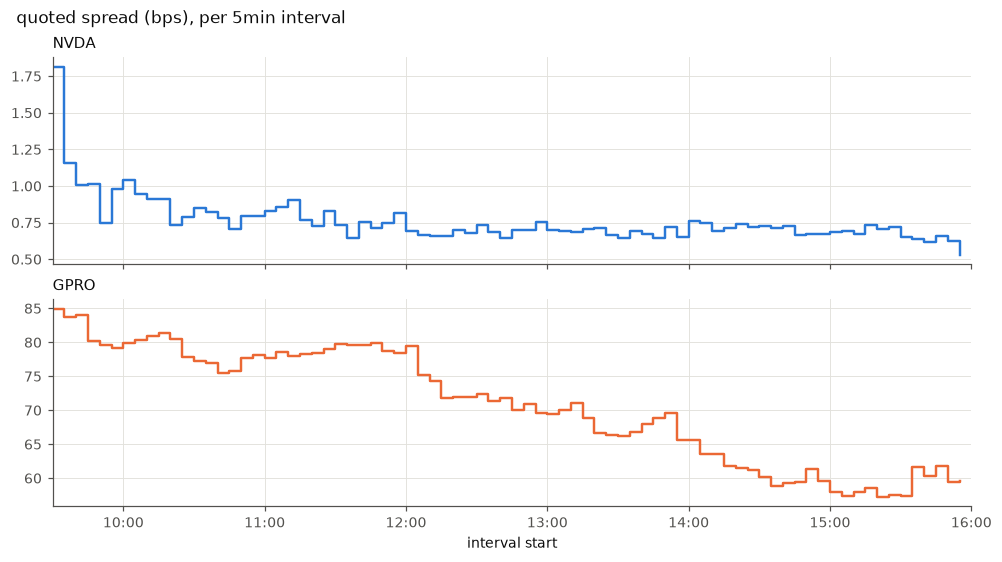

In [19]:
plots.plot_liquidity(days, "spread_bps", save="eq_spread_bps_5min");

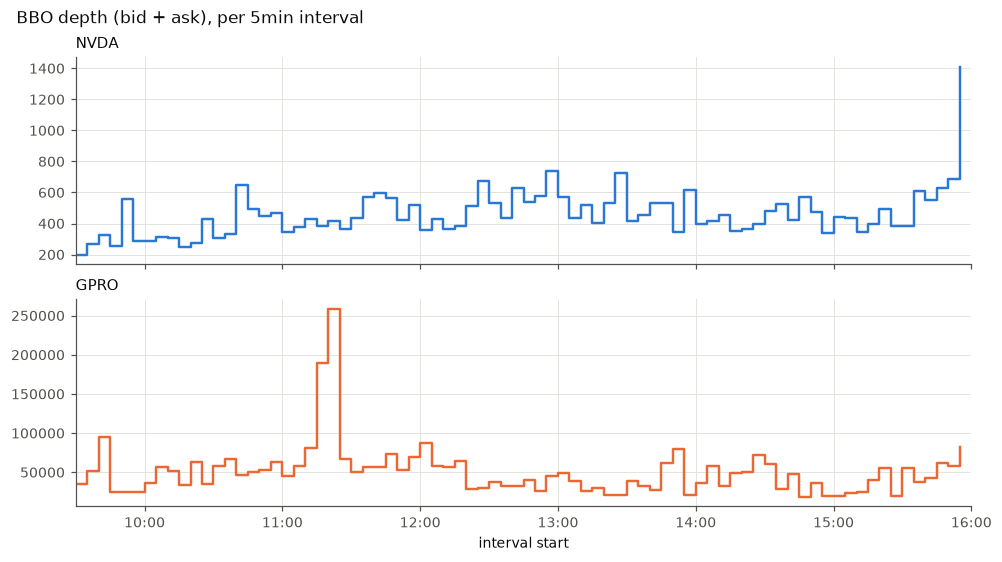

In [20]:
plots.plot_liquidity(days, "depth", save="eq_depth_5min");

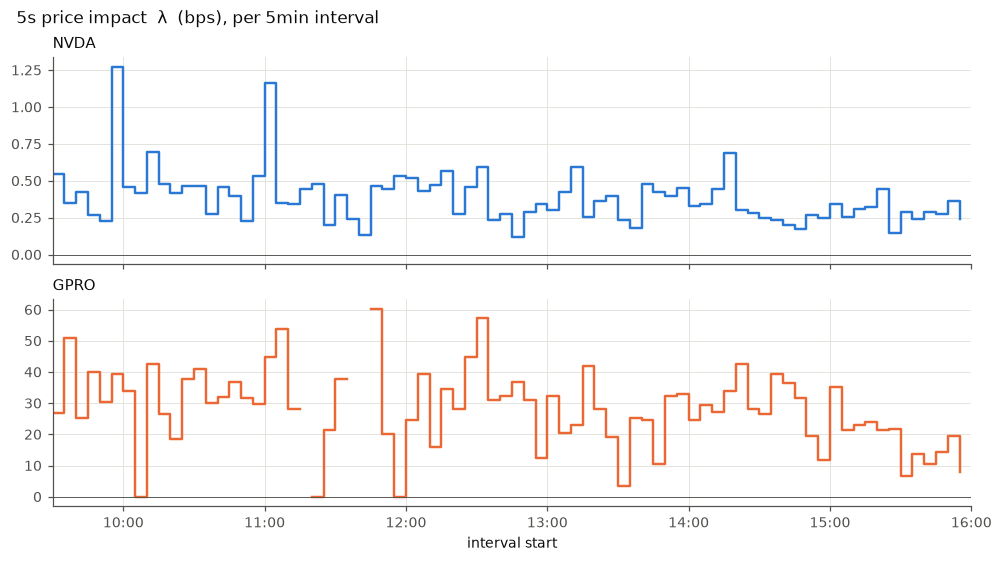

In [21]:
plots.plot_liquidity(days, "lambda_bps", save="eq_lambda_bps_5min");

### One-minute transaction returns by half hour

Thirty one-minute returns per interval, so the lag-1 autocorrelation is estimated
on 29 pairs and the dashed lines at ±1.96/√n show how little a single half hour can
say on its own; the shape across the day is the thing to read.

In [22]:
ret30 = {s: plots.returns_by_interval(d) for s, d in days.items()}
pd.concat(ret30, axis=1, names=["symbol", ""]).round(3)

symbol                             NVDA                     GPRO           
                          variance_bps2    ac1   n variance_bps2    ac1   n
2026-09-02 09:30:00-04:00       236.704 -0.123  29     10628.107 -0.100  29
2026-09-02 10:00:00-04:00        85.350 -0.192  30      4308.339  0.222  30
2026-09-02 10:30:00-04:00        63.814 -0.163  30      5229.140  0.047  30
2026-09-02 11:00:00-04:00       155.359 -0.276  30      1767.182  0.159  30
2026-09-02 11:30:00-04:00       112.893 -0.507  30       944.050  0.079  30
2026-09-02 12:00:00-04:00        47.069 -0.254  30      6801.568  0.100  30
2026-09-02 12:30:00-04:00        32.126 -0.100  30      6347.600  0.124  30
2026-09-02 13:00:00-04:00        41.266  0.241  30     11920.470 -0.164  30
2026-09-02 13:30:00-04:00        29.018 -0.120  30     12889.813  0.202  30
2026-09-02 14:00:00-04:00        43.823 -0.248  30      6661.854 -0.129  30
2026-09-02 14:30:00-04:00        18.560  0.107  30     10573.867 -0.067  30
2026-09-02 15:00:00-04:00        15.069  0.217  30      8819.393 -0.006  30
2026-09-02 15:30:00-04:00        29.708  0.044  30      3683.015  0.024  30

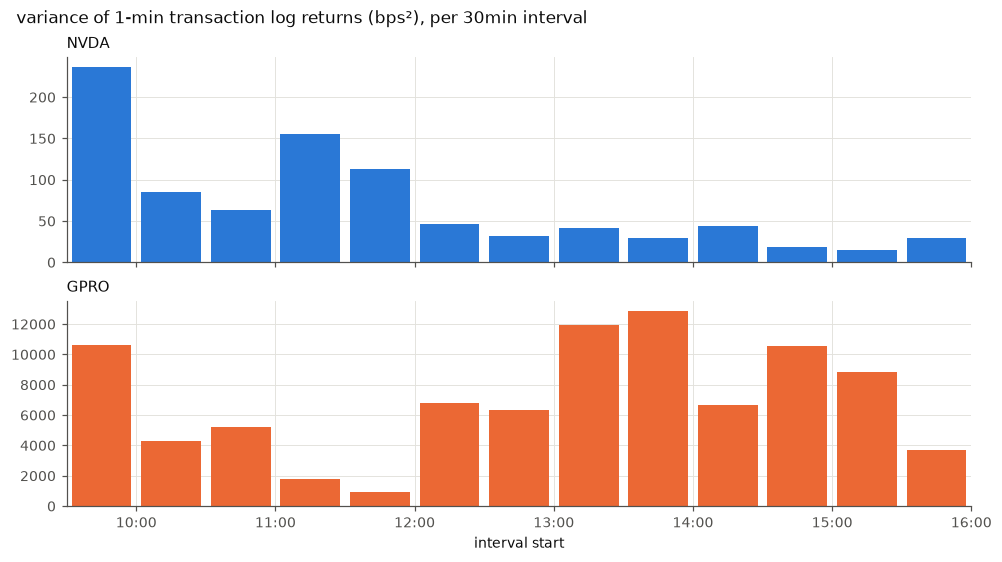

In [23]:
plots.plot_returns(days, "variance_bps2", save="eq_variance_bps2_30min");

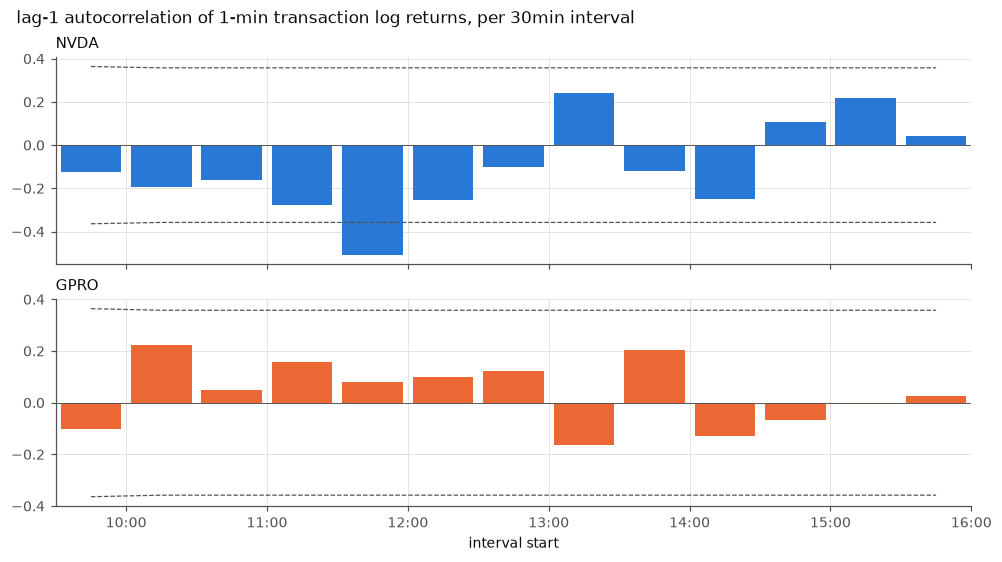

In [24]:
plots.plot_returns(days, "ac1", save="eq_ac1_30min");

### Autocorrelation functions

One row per stock, midquote on the left and transaction price on the right; the
shaded band is ±1.96/√n.

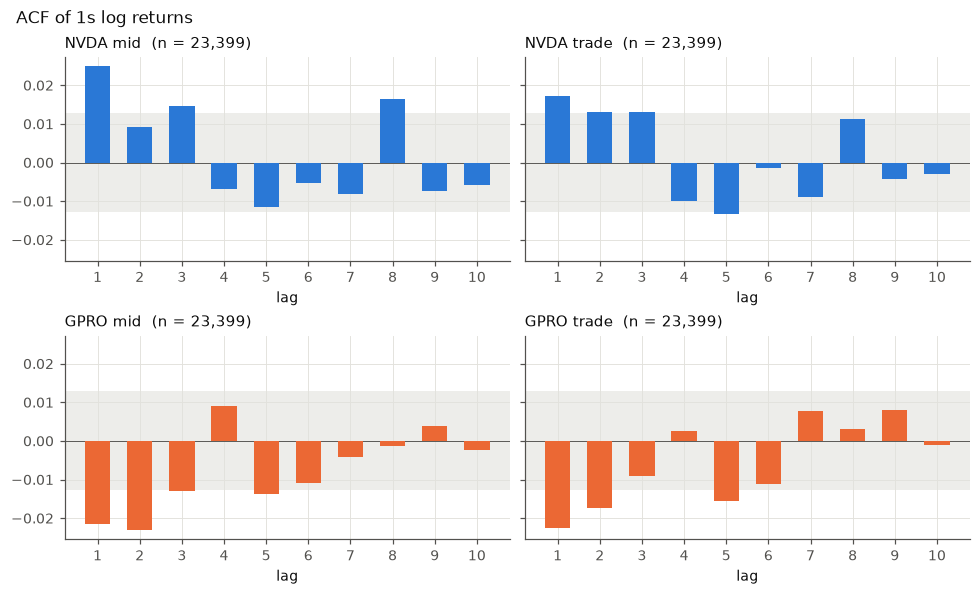

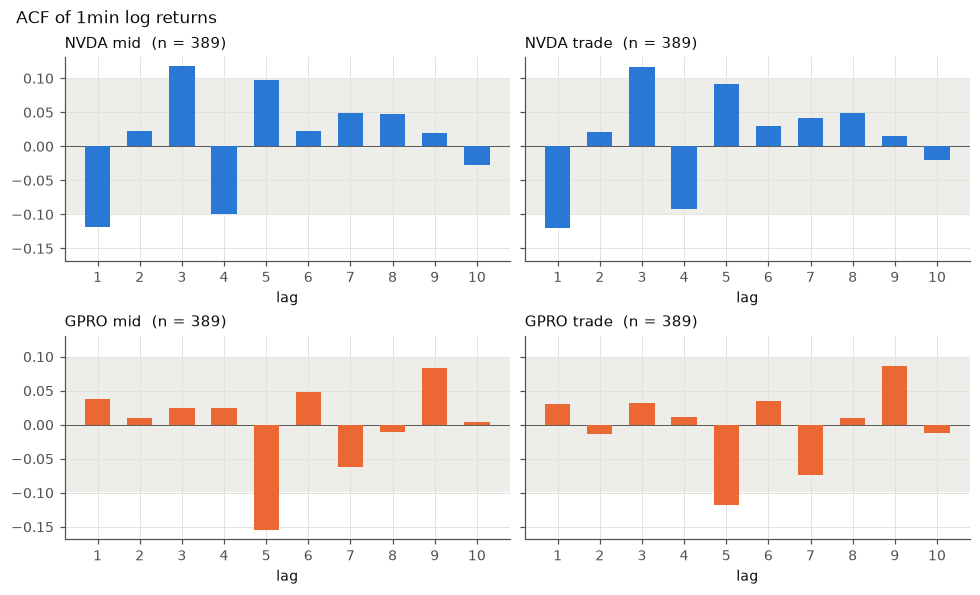

In [25]:
for _fq in FREQS:
    plots.plot_acf({f"{s} {k}": i[s][_fq][k] for s in days for k in ("mid", "trade")},
                   lags=10, save=f"eq_acf_{_fq}", title=f"ACF of {_fq} log returns")

## Summary statistics table

Every part at the daily level, one column per stock; the same `hfstats.headline`
column the currencies notebook produces, so the two panels stack into one table.
Dollar volume is in dollars and depth in shares here, against USD millions and
millions of base currency for the pairs, so only the relative rows compare across.

In [26]:
table = pd.DataFrame({s: hs.headline(d) for s, d in days.items()})
table.to_csv(plots.FIG_DIR / "summary_equities.csv")
table.round(4)

,NVDA,GPRO
(a) dollar volume / min,1.310379e+07,7.210494e+04
(b) trades / min,8.917462e+02,7.515640e+01
(b) orders or book messages / min,2.547977e+04,8.663615e+02
(c) open,2.188700e+02,1.220000e+00
(c) high,2.279400e+02,1.790000e+00
(c) low,2.184700e+02,1.180000e+00
(c) close,2.244000e+02,1.705000e+00
"(d) VWAP, session",2.243533e+02,1.519100e+00
(e) spread,1.700000e-02,1.000000e-02
(e) spread (bps),7.574000e-01,7.065530e+01


## Observations

1. **Size sets the spread, but not the dollar depth.** NVDA quotes 1.7 cents wide
   (0.76 bps) and GPRO 1.0 cent (71 bps): a 93x gap in relative terms that is almost
   entirely the tick. GPRO sits at the one-cent minimum in 99.6% of seconds, so its
   spread in basis points is just the inverse of its price — 85 bps in the first five
   minutes at \$1.22, 59 bps in the last at \$1.70 — and the "narrowing" through the
   day in the spread figure is the rally, not a liquidity change. NVDA is one tick
   wide only 41% of the time, so its spread does carry information. Depth at the touch
   is where the tick-constraint prediction bites: GPRO rests 50,700 shares at the BBO
   against NVDA's 462 — but in dollars that is \$73k against \$104k, the same order of
   magnitude, not "far thinner". A one-cent spread on a \$1.50 stock is such a wide
   gate that the queue behind it is long; the band measure (f) shows the same thing,
   since for GPRO the ±1-spread band never reaches past the touch. Volume tells the
   size story more honestly: \$5.1bn against \$28mm on the day, 892 against 75 prints
   a minute, 14 displayed orders per trade against 5, and a cancel-to-add ratio of
   about one for both — nearly every displayed order is cancelled rather than filled.
   NVDA's tape is 74% odd lots (median print 25 shares); GPRO's median print is a
   round lot.
2. **Impact is larger for GPRO in basis points and smaller in cents.** Pooled over the
   session with HAC errors, λ is 0.46 bps for NVDA (t = 28) and 26.7 bps for GPRO
   (t = 28); the per-minute means are 0.33 and 22.7 bps, lower because thin minutes
   weigh as much as busy ones. In price units that is 1.0 cent for NVDA — a signed
   trade moves the mid by about one tick, roughly 0.6 of its spread, within five
   seconds — and 0.4 cents for GPRO, less than half a tick. GPRO's mid can only move
   in half-cent steps, so 26.7 bps is the *probability* that a trade shifts the touch
   times the 29–41 bps that one half-tick is worth at its price; its λ falls through
   the afternoon in the figure for the same mechanical reason its spread does.
   NVDA's λ is highest in the first five minutes (0.55 bps) with spikes to 1.3 at
   09:55 and 1.2 at 11:00, and lowest into the close (0.24).
3. **Bounce is weak in both names; what shows up instead is discreteness and a
   transitory component at one minute.** For NVDA, transaction RV at one second
   exceeds midquote RV by only 1.8% (33,019 against 32,435 bps²), and the lag-1
   autocorrelation of one-second returns is *positive* for both series (+0.017 trade,
   +0.025 mid, Box–Pierce p < 0.01): with 15 prints a second, mostly odd lots inside
   or at a 1.7-cent spread, the last trade of each second is essentially the touch,
   and what the ACF picks up is gradual quote adjustment, not Roll's bounce. The
   volatility signature is two-sided: the midquote RV *rises* from 32,400 bps² at one
   second to 35,000 at thirty seconds (21% of one-second mid returns are exactly zero,
   so discreteness holds the fine-grid figure down, as it does for the EBS mids) and
   then falls to 27,300 at one minute and 22,300 at five, where a transitory component
   averages out. That component is visible directly: the lag-1 autocorrelation of
   one-minute returns is −0.12 for the mid and −0.12 for trades (p = 0.02), negative in
   nine of thirteen half hours and −0.51 in 11:30–12:00, and it is in the *mid*, so it
   is not bid–ask bounce. GPRO is the discreteness case: 97% of its one-second
   midquote returns and 94% of its transaction returns are zero, yet its RV falls
   monotonically from 2.83 million bps² at one second to 2.40 million at thirty
   seconds and is flat after that, its one-second returns are negatively
   autocorrelated in both series (−0.02, p < 0.001), and trade RV exceeds mid RV at
   every frequency — the standard bounce signature, faint but there, from a print
   that alternates between a bid and an ask one cent apart. Its one-minute returns
   show no autocorrelation at all (p = 0.45). The session RV is 1.8% for NVDA and
   16.8% for GPRO — a 40% day.
4. **The U is half a U.** NVDA's opening half hour is the extreme of everything:
   spread 1.8 bps in the first five minutes against 0.66 at noon, depth 200 shares
   against 360, and the variance of one-minute returns 237 bps² against 15 in the
   15:00 half hour — sixteen times. But there is no second arm. Spread and impact fall
   monotonically to their lows in the last five minutes (0.53 bps, 0.24 bps) while
   depth triples to 1,410 shares and the busiest minute of the day is 15:59 with
   675k shares: the closing auction attracts resting liquidity and volume without
   widening anything, the opposite of the open. The variance ticks up only slightly in
   the last half hour (30 against 15 bps²). The classic pattern is a U in *volume*
   and an L in *cost*. GPRO's day is shaped by its own news rather than the clock:
   half-hour variance peaks at 12,900 bps² in 13:30–14:00, during the rally, not at
   the open (10,600), and the largest one-minute move (+4.3%) is at 13:55. While it
   trends the lag-1 autocorrelation of its one-minute returns is positive in most half
   hours (+0.22, +0.16, +0.20), the same momentum-while-trending sign the EUR/USD
   series shows going into the FOMC release. Its cancel-to-add ratio is 1.03 for the
   day; NVDA's is 0.97, with the 09:30 minute alone carrying 160k add messages against a
   median of 9,900 — the fleeting-liquidity burst is an opening phenomenon.